#  1. Imports and Environment Setup

In [ ]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
import matplotlib.pyplot as plt
import numpy as np

In [3]:
def setup_gpu_environment():
    """
    Setup GPU environment: list available GPUs and enable memory growth for each GPU.
    This prevents TensorFlow from allocating all the GPU memory at once.
    """
    gpus = tf.config.list_physical_devices('GPU')
    if gpus:
        try:
            # Enable memory growth for each GPU
            for gpu in gpus:
                tf.config.experimental.set_memory_growth(gpu, True)
            logical_gpus = tf.config.list_logical_devices('GPU')
            print(f"{len(gpus)} Physical GPUs, {len(logical_gpus)} Logical GPUs configured.")
        except RuntimeError as e:
            # Memory growth must be set before GPUs have been initialized
            print("Error setting up GPU memory growth:", e)
    else:
        print("No GPU found. Running on CPU.")

# Execute the function to setup the GPU environment
setup_gpu_environment()

No GPU found. Running on CPU.


# 2. Define Parameters and Data Paths

In [6]:
BASE_DIR = 'C:\\Users\\tanis\\OneDrive\\Documents\\final year project\\archive\\A NEW DATASET SPLIT'  # This directory should contain 'train', 'valid', and 'test' folders

train_dir = os.path.join(BASE_DIR, 'train')
val_dir   = os.path.join(BASE_DIR, 'valid')
test_dir  = os.path.join(BASE_DIR, 'test')

# Hyperparameters
BATCH_SIZE = 32
IMG_SIZE = (224, 224)  # Adjust depending on your pre-trained model requirements
NUM_CLASSES = 4      # Corresponding to [both, infection, ischaemia, none]

# 3. Data Loading and Preprocessing

In [7]:
# Load training dataset
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    labels='inferred',
    label_mode='categorical',  # one-hot encoding
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=True
)

# Load validation dataset
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir,
    labels='inferred',
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=True
)

# Load test dataset
test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    labels='inferred',
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

Found 12604 files belonging to 4 classes.
Found 4193 files belonging to 4 classes.
Found 1193 files belonging to 4 classes.


In [8]:
# Optimize dataset performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds   = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds  = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

# 4. Data Augmentation

In [9]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

# 5. Model Building Function

In [16]:
class MultiScaleAttentionBlock(layers.Layer):
    def __init__(self, filters, **kwargs):
        super(MultiScaleAttentionBlock, self).__init__(**kwargs)
        self.filters = filters
        
        # Multi-scale convolution branches
        self.conv3x3 = layers.Conv2D(filters, (3, 3), padding='same', activation='relu')
        self.conv5x5 = layers.Conv2D(filters, (5, 5), padding='same', activation='relu')
        self.conv7x7 = layers.Conv2D(filters, (7, 7), padding='same', activation='relu')
        self.concat = layers.Concatenate()
        
        # Squeeze and Excitation components
        self.global_pool = layers.GlobalAveragePooling2D()
        self.fc1 = layers.Dense(filters, activation='relu')
        self.fc2 = layers.Dense(filters * 3, activation='sigmoid')
        self.reshape_se = layers.Reshape((1, 1, filters * 3))
        self.multiply = layers.Multiply()
        
        # Multi-Head Self-Attention
        # Note: key_dim should divide filters; here we use filters//4 assuming filters>=4.
        self.mha = layers.MultiHeadAttention(num_heads=4, key_dim=filters//4)
        
    def call(self, inputs):
        # Multi-scale convolutions
        branch_3 = self.conv3x3(inputs)
        branch_5 = self.conv5x5(inputs)
        branch_7 = self.conv7x7(inputs)
        
        # Concatenate the multi-scale features along the channel axis
        multi_scale = self.concat([branch_3, branch_5, branch_7])
        
        # Squeeze-and-Excitation: compute channel-wise weights
        se = self.global_pool(multi_scale)
        se = self.fc1(se)
        se = self.fc2(se)
        se = self.reshape_se(se)
        scaled = self.multiply([multi_scale, se])
        
        # Obtain static spatial dimensions using K.int_shape (returns a tuple)
        _, h, w, c = tf.keras.backend.int_shape(scaled)
        # Reshape feature map to (batch, h*w, c) for self-attention
        flatten = tf.reshape(scaled, (-1, h * w, c))
        attn_output = self.mha(flatten, flatten)
        # Reshape back to (batch, h, w, c)
        output = tf.reshape(attn_output, (-1, h, w, c))
        return output

    def get_config(self):
        config = super(MultiScaleAttentionBlock, self).get_config()
        config.update({"filters": self.filters})
        return config

In [17]:
def build_wound_fusion_net(input_shape=(224, 224, 3), num_classes=4):
    """
    Builds the WoundFusionNet model for diabetic wound classification.
    It uses EfficientNetB0 as a backbone and fuses global context with
    fine-grained, attention-refined features.
    """
    # Load EfficientNetB0 as a feature extractor (exclude top classifier)
    base_model = EfficientNetB0(include_top=False, weights='imagenet', input_shape=input_shape)
    base_model.trainable = False  # Freeze the base model for transfer learning

    inputs = layers.Input(shape=input_shape)
    features = base_model(inputs, training=False)  # Extract feature maps from input

    # Branch 1: Global Context using Global Average Pooling
    gap = layers.GlobalAveragePooling2D()(features)
    branch_global = layers.Dense(128, activation='relu')(gap)
    
    # Branch 2: Fine-Grained Features via Multi-Scale Attention
    attn_block = MultiScaleAttentionBlock(filters=32)
    attn_features = attn_block(features)
    gap_attn = layers.GlobalAveragePooling2D()(attn_features)
    branch_attn = layers.Dense(128, activation='relu')(gap_attn)
    
    # Fuse the two branches
    fused = layers.Concatenate()([branch_global, branch_attn])
    fused = layers.Dense(128, activation='relu')(fused)
    fused = layers.Dropout(0.5)(fused)
    
    # Final classification layer
    outputs = layers.Dense(num_classes, activation='softmax')(fused)
    
    model = models.Model(inputs, outputs, name='WoundFusionNet')
    return model

In [18]:
model = build_wound_fusion_net(input_shape=(224,224,3), num_classes=4)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step



Model: "WoundFusionNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ input_layer_1[0]… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_attent… │ (None, 7, 7, 96)  │  3,418,528 │ efficientnetb0[0… │
│ (MultiScaleAttenti… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ multi_scale_atte… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    163,968 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │     12,416 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256)       │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     32,896 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 4)         │        516 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,677,895 (29.29 MB)

 Trainable params: 3,628,324 (13.84 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

# 6. Train the model

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Set training hyperparameters
EPOCHS = 20

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/20
394/394 ━━━━━━━━━━━━━━━━━━━━ 98s 183ms/step - accuracy: 0.5230 - loss: 1.0355 - val_accuracy: 0.7396 - val_loss: 0.6629
Epoch 2/20
394/394 ━━━━━━━━━━━━━━━━━━━━ 19s 47ms/step - accuracy: 0.7890 - loss: 0.5173 - val_accuracy: 0.7634 - val_loss: 0.6255
Epoch 3/20
394/394 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.8571 - loss: 0.3524 - val_accuracy: 0.7572 - val_loss: 0.6843
Epoch 4/20
394/394 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.8877 - loss: 0.2744 - val_accuracy: 0.7825 - val_loss: 0.6795
Epoch 5/20
394/394 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.9128 - loss: 0.2218 - val_accuracy: 0.7682 - val_loss: 0.7542
Epoch 6/20
394/394 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.9366 - loss: 0.1667 - val_accuracy: 0.7944 - val_loss: 0.6854
Epoch 7/20
394/394 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.9463 - loss: 0.1441 - val_accuracy: 0.7758 - val_loss: 0.7728
Epoch 8/20
394/394 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.9565 - loss: 0.1171 -

# 7. Visualise Model Training History

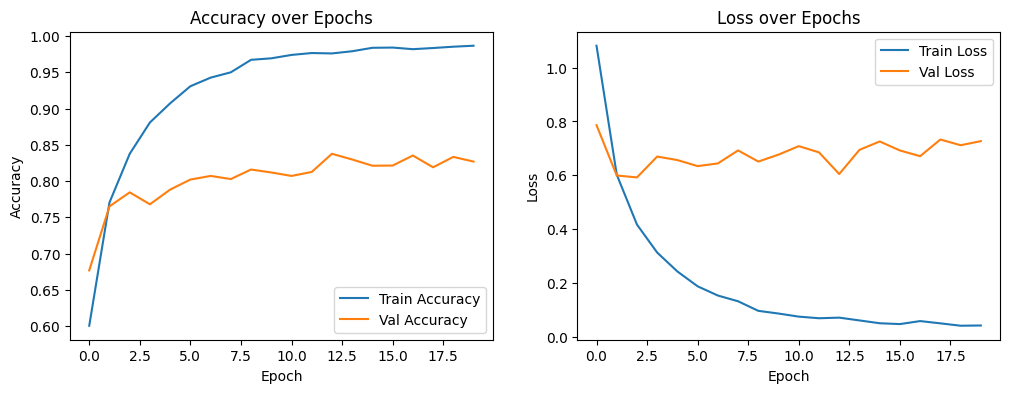

In [37]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

# 8. Evaluate Model Performance 

In [15]:
test_loss, test_accuracy = model.evaluate(test_ds)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 207ms/step - accuracy: 0.8303 - loss: 0.7053
Test Loss: 0.9521
Test Accuracy: 0.7754


# 9. Save and Upload Model to Kaggle Models

In [45]:
import kagglehub
from kagglehub.config import get_kaggle_credentials

# Other ways to authenticate also available: https://github.com/Kaggle/kagglehub?tab=readme-ov-file#authenticate
kagglehub.login()

In [44]:
# save model
model_v3.save('/kaggle/working/diabetic_wound_classifier.keras')
print("Model saved successfully!")

Model saved successfully!


## Above Model V1 - Test Accuracy - 77.5%

# 10.Updated Newer Model

## V2 Model Architecture Modification

In [19]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

# Define a custom layer for multi-scale attention with increased filters
class MultiScaleAttentionBlock(layers.Layer):
    def __init__(self, filters, **kwargs):
        super(MultiScaleAttentionBlock, self).__init__(**kwargs)
        self.filters = filters
        
        # Multi-scale convolution branches with different kernel sizes
        self.conv3x3 = layers.Conv2D(filters, (3, 3), padding='same', activation='relu')
        self.conv5x5 = layers.Conv2D(filters, (5, 5), padding='same', activation='relu')
        self.conv7x7 = layers.Conv2D(filters, (7, 7), padding='same', activation='relu')
        self.concat = layers.Concatenate()
        
        # Squeeze-and-Excitation components
        self.global_pool = layers.GlobalAveragePooling2D()
        self.fc1 = layers.Dense(filters, activation='relu')
        self.fc2 = layers.Dense(filters * 3, activation='sigmoid')
        self.reshape_se = layers.Reshape((1, 1, filters * 3))
        self.multiply = layers.Multiply()
        
        # Multi-head self-attention
        self.mha = layers.MultiHeadAttention(num_heads=4, key_dim=filters // 4)
    
    def call(self, inputs):
        # Obtain multi-scale features
        branch_3 = self.conv3x3(inputs)
        branch_5 = self.conv5x5(inputs)
        branch_7 = self.conv7x7(inputs)
        multi_scale = self.concat([branch_3, branch_5, branch_7])
        
        # Squeeze-and-Excitation to generate channel-wise weights
        se = self.global_pool(multi_scale)
        se = self.fc1(se)
        se = self.fc2(se)
        se = self.reshape_se(se)
        scaled = self.multiply([multi_scale, se])
        
        # Reshape for self-attention: (batch, h*w, channels)
        _, h, w, c = tf.keras.backend.int_shape(scaled)
        flatten = tf.reshape(scaled, (-1, h * w, c))
        attn_output = self.mha(flatten, flatten)
        output = tf.reshape(attn_output, (-1, h, w, c))
        return output
    
    def get_config(self):
        config = super(MultiScaleAttentionBlock, self).get_config()
        config.update({"filters": self.filters})
        return config

In [20]:
def build_wound_fusion_net_v2(input_shape=(224, 224, 3), num_classes=4):
    """
    Builds the updated WoundFusionNet_v2 model.
    Modifications include:
      - Partial fine-tuning of EfficientNetB0 (unfreezing the top 20 layers)
      - Increased filters in the attention block
      - BatchNormalization layers for stable training
      - Residual fusion of global and attention branches
    """
    # Load EfficientNetB0 as backbone (exclude top classifier)
    base_model = EfficientNetB0(include_top=False, weights='imagenet', input_shape=input_shape)
    
    # Unfreeze top 20 layers for fine-tuning while keeping lower layers frozen
    for layer in base_model.layers[:-20]:
        layer.trainable = False
    for layer in base_model.layers[-20:]:
        layer.trainable = True
    
    inputs = layers.Input(shape=input_shape)
    features = base_model(inputs, training=False)
    
    # Global Branch: Global Average Pooling and Dense layer
    gap = layers.GlobalAveragePooling2D()(features)
    branch_global = layers.Dense(128, activation='relu')(gap)
    branch_global = layers.BatchNormalization()(branch_global)
    
    # Attention Branch: Multi-scale attention with increased filters and Dense layer
    attn_block = MultiScaleAttentionBlock(filters=48)
    attn_features = attn_block(features)
    gap_attn = layers.GlobalAveragePooling2D()(attn_features)
    branch_attn = layers.Dense(128, activation='relu')(gap_attn)
    branch_attn = layers.BatchNormalization()(branch_attn)
    
    # Fuse branches using residual (Add) connection
    fused = layers.Add()([branch_global, branch_attn])
    fused = layers.Dense(128, activation='relu')(fused)
    fused = layers.BatchNormalization()(fused)
    fused = layers.Dropout(0.5)(fused)
    
    # Final classification layer with softmax activation for 4 classes
    outputs = layers.Dense(num_classes, activation='softmax')(fused)
    
    model = models.Model(inputs, outputs, name='WoundFusionNet_v2')
    return model

In [21]:
# Build the updated model and display its summary
model_v2 = build_wound_fusion_net_v2(input_shape=(224, 224, 3), num_classes=4)
model_v2.summary()

Model: "WoundFusionNet_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5             │ (None, 224, 224, 3)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ efficientnetb0            │ (None, 7, 7, 1280)     │      4,049,571 │ input_layer_5[0][0]    │
│ (Functional)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ multi_scale_attention_bl… │ (None, 7, 7, 144)      │      5,141,616 │ efficientnetb0[0][0]   │
│ (MultiScaleAttentionBloc… │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ global_average_pooling2d… │ (None, 1280)           │              0 │ efficientnetb0[0][0]   │
│ (GlobalAveragePooling2D)  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ global_average_pooling2d… │ (None, 144)            │              0 │ multi_scale_attention… │
│ (GlobalAveragePooling2D)  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_9 (Dense)           │ (None, 128)            │        163,968 │ global_average_poolin… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_12 (Dense)          │ (None, 128)            │         18,560 │ global_average_poolin… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 128)            │            512 │ dense_9[0][0]          │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 128)            │            512 │ dense_12[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add (Add)                 │ (None, 128)            │              0 │ batch_normalization[0… │
│                           │                        │                │ batch_normalization_1… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_13 (Dense)          │ (None, 128)            │         16,512 │ add[0][0]              │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 128)            │            512 │ dense_13[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_3 (Dropout)       │ (None, 128)            │              0 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_14 (Dense)          │ (None, 4)              │            516 │ dropout_3[0][0]        │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 9,392,279 (35.83 MB)

 Trainable params: 6,692,900 (25.53 MB)

 Non-trainable params: 2,699,379 (10.30 MB)

## V3. Model Structure

In [2]:
import tensorflow as tf
from tensorflow.keras import layers

class MultiScaleAttentionBlock(layers.Layer):
    def __init__(self, filters, **kwargs):
        super(MultiScaleAttentionBlock, self).__init__(**kwargs)
        self.filters = filters

        # Multi-scale convolution branches
        self.conv3x3 = layers.Conv2D(filters, (3, 3), padding='same', activation='relu')
        self.conv5x5 = layers.Conv2D(filters, (5, 5), padding='same', activation='relu')
        self.conv7x7 = layers.Conv2D(filters, (7, 7), padding='same', activation='relu')
        self.concat = layers.Concatenate()

        # Squeeze-and-Excitation
        self.global_pool = layers.GlobalAveragePooling2D()
        self.fc1 = layers.Dense(filters, activation='relu')
        self.fc2 = layers.Dense(filters * 3, activation='sigmoid')
        self.reshape_se = layers.Reshape((1, 1, filters * 3))
        self.multiply = layers.Multiply()

        # Multi-Head Self-Attention
        self.mha = layers.MultiHeadAttention(num_heads=4, key_dim=max(filters // 4, 1))

    def call(self, inputs):
        # Multi-scale feature extraction
        branch_3 = self.conv3x3(inputs)
        branch_5 = self.conv5x5(inputs)
        branch_7 = self.conv7x7(inputs)
        multi_scale = self.concat([branch_3, branch_5, branch_7])

        # Squeeze-and-Excitation
        se = self.global_pool(multi_scale)
        se = self.fc1(se)
        se = self.fc2(se)
        se = self.reshape_se(se)
        scaled = self.multiply([multi_scale, se])

        # Reshape for Self-Attention
        _, h, w, c = tf.keras.backend.int_shape(scaled)
        flatten = tf.reshape(scaled, (-1, h * w, c))
        attn_output = self.mha(flatten, flatten)
        output = tf.reshape(attn_output, (-1, h, w, c))
        return output

    def get_config(self):
        config = super(MultiScaleAttentionBlock, self).get_config()
        config.update({"filters": self.filters})
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

In [21]:
def build_wound_fusion_net_v3(input_shape=(224, 224, 3), num_classes=4):
    """
    Builds the updated WoundFusionNet_v3 model with:
      - Top-30 layers of EfficientNetB0 unfrozen for fine-tuning
      - An enhanced multi-scale attention block with increased filters
      - A gated fusion mechanism to adaptively combine global and attention branch features
      - Additional batch normalization and dropout for better generalization.
    """
    # Load EfficientNetB0 backbone with ImageNet weights (excluding top)
    base_model = EfficientNetB0(include_top=False, weights='imagenet', input_shape=input_shape)
    # Unfreeze the top 30 layers for fine-tuning
    for layer in base_model.layers[:-30]:
        layer.trainable = False
    for layer in base_model.layers[-30:]:
        layer.trainable = True
    
    inputs = layers.Input(shape=input_shape)
    features = base_model(inputs, training=False)
    
    # Global Branch: extract global features using GAP and a Dense layer
    gap = layers.GlobalAveragePooling2D()(features)
    branch_global = layers.Dense(128, activation='relu')(gap)
    branch_global = layers.BatchNormalization()(branch_global)
    
    # Attention Branch: use the multi-scale attention block and GAP
    attn_block = MultiScaleAttentionBlock(filters=64)
    attn_features = attn_block(features)
    gap_attn = layers.GlobalAveragePooling2D()(attn_features)
    branch_attn = layers.Dense(128, activation='relu')(gap_attn)
    branch_attn = layers.BatchNormalization()(branch_attn)
    
    # Gated Fusion: Learn a gate to adaptively weight the two branches
    concatenated = layers.Concatenate()([branch_global, branch_attn])
    gate = layers.Dense(128, activation='sigmoid')(concatenated)
    fused = layers.Add()([
        layers.Multiply()([gate, branch_global]),
        layers.Multiply()([1 - gate, branch_attn])
    ])
    
    # Final classification head with additional dense layers, BN, and dropout
    x = layers.Dense(128, activation='relu')(fused)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = models.Model(inputs, outputs, name='WoundFusionNet_v3')
    return model

In [22]:
model_v3 = build_wound_fusion_net_v3(input_shape=(224, 224, 3), num_classes=4)
model_v3.summary()

Model: "WoundFusionNet_v3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ input_layer_3[0]… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_attent… │ (None, 7, 7, 192) │  6,873,920 │ efficientnetb0[0… │
│ (MultiScaleAttenti… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 192)       │          0 │ multi_scale_atte… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │    163,968 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 128)       │     24,704 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ dense_6[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_9[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 256)       │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 128)       │     32,896 │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract (Subtract) │ (None, 128)       │          0 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_2          │ (None, 128)       │          0 │ dense_10[0][0],   │
│ (Multiply)          │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_3          │ (None, 128)       │          0 │ subtract[0][0],   │
│ (Multiply)          │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128)       │          0 │ multiply_2[0][0], │
│                     │                   │            │ multiply_3[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 128)       │     16,512 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_11[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 4)         │        516 │ dropout_3[0][0] 

 Total params: 11,163,623 (42.59 MB)

 Trainable params: 8,609,444 (32.84 MB)

 Non-trainable params: 2,554,179 (9.74 MB)

## 10.2 Train the Model

In [23]:
model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Set training hyperparameters
EPOCHS = 10

# Train the model
history = model_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10


 55/394 ━━━━━━━━━━━━━━━━━━━━ 4:55 871ms/step - accuracy: 0.3743 - loss: 1.8405

KeyboardInterrupt: 

# 11. Plot Confusion Matrix

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [25]:
def plot_confusion_matrix(y_true, y_pred, class_names):
    """
    Plots the confusion matrix using seaborn heatmap.
    
    Args:
        y_true (list or array): True labels.
        y_pred (list or array): Predicted labels.
        class_names (list): List of class names.
    """
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix")
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━

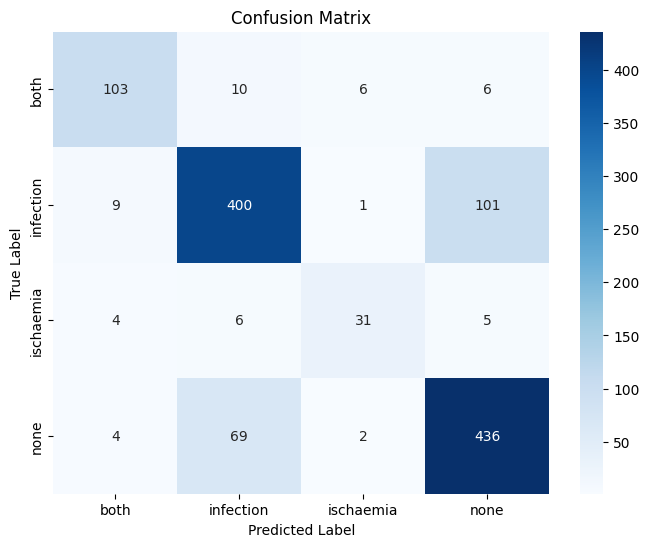

In [36]:
y_true = []
y_pred = []

# Iterate through the test dataset and collect predictions
for images, labels in test_ds:
    preds = model_v3.predict(images)  # Using our updated model, for example
    y_true.extend(np.argmax(labels, axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

# Define the class names based on your dataset directory structure:
# "both", "infection", "ischaemia", "none"
class_names = ['both', 'infection', 'ischaemia', 'none']

# Plot the confusion matrix
plot_confusion_matrix(y_true, y_pred, class_names)

In [35]:
test_loss, test_accuracy = model_v3.evaluate(test_ds)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 152ms/step - accuracy: 0.8023 - loss: 0.8132
Test Loss: 0.7467
Test Accuracy: 0.8131


# 12. Load Trained Model

In [47]:
model_path = "/kaggle/input/woundfusionnet/tensorflow2/4/1/diabetic_wound_classifier.keras"

In [49]:
from tensorflow.keras.utils import get_custom_objects

get_custom_objects().update({'MultiScaleAttentionBlock': MultiScaleAttentionBlock})

model = tf.keras.models.load_model(model_path)
model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/layer.py:391: UserWarning: `build()` was called on layer 'multi_scale_attention_block_4', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "WoundFusionNet_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9             │ (None, 224, 224, 3)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ efficientnetb0            │ (None, 7, 7, 1280)     │      4,049,571 │ input_layer_9[0][0]    │
│ (Functional)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ multi_scale_attention_bl… │ (None, 7, 7, 192)      │      6,873,920 │ efficientnetb0[0][0]   │
│ (MultiScaleAttentionBloc… │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ global_average_pooling2d… │ (None, 1280)           │              0 │ efficientnetb0[0][0]   │
│ (GlobalAveragePooling2D)  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ global_average_pooling2d… │ (None, 192)            │              0 │ multi_scale_attention… │
│ (GlobalAveragePooling2D)  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_43 (Dense)          │ (None, 128)            │        163,968 │ global_average_poolin… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_46 (Dense)          │ (None, 128)            │         24,704 │ global_average_poolin… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_9     │ (None, 128)            │            512 │ dense_43[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_10    │ (None, 128)            │            512 │ dense_46[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate_17            │ (None, 256)            │              0 │ batch_normalization_9… │
│ (Concatenate)             │                        │                │ batch_normalization_1… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_47 (Dense)          │ (None, 128)            │         32,896 │ concatenate_17[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ subtract_3 (Subtract)     │ (None, 128)            │              0 │ dense_47[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ multiply_19 (Multiply)    │ (None, 128)            │              0 │ dense_47[0][0],        │
│                           │                        │                │ batch_normalization_9… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ multiply_20 (Multiply)    │ (None, 128)            │              0 │ subtract_3[0][0],      │
│                           │                        │                │ batch_normalization_1… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add_3 (Add)          

 Total params: 28,382,513 (108.27 MB)

 Trainable params: 8,609,444 (32.84 MB)

 Non-trainable params: 2,554,179 (9.74 MB)

 Optimizer params: 17,218,890 (65.68 MB)

In [ ]:
y_true =[]
y_pred = []
count=0
for images, labels in test_ds:
    preds = model_v3.predict(images)  # Using our updated model, for example
    y_true.extend(np.argmax(labels, axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

# Define the class names based on your dataset directory structure:
# "both", "infection", "ischaemia", "none"
class_names = ['both', 'infection', 'ischaemia', 'none']

In [ ]:
import tensorflow as tf
import numpy as np
from PIL import Image
from tensorflow.keras.utils import get_custom_objects

get_custom_objects().update({'MultiScaleAttentionBlock': MultiScaleAttentionBlock})

# Load the trained model
model_path = 'diabetic_wound_classifier.keras'  # update with your model's path
model = tf.keras.models.load_model(model_path)

def load_and_preprocess_image(image_path, target_size=(224, 224)):
    """
    Load an image from disk and preprocess it:
    - Converts the image to RGB
    - Resizes it to the target size (default is 224x224)
    - Normalizes pixel values to the range [0, 1]
    - Adds an extra batch dimension for prediction
    """
    # Open the image and convert to RGB
    img = Image.open(image_path).convert('RGB')
    # Resize the image to the target dimensions
    img = img.resize(target_size)
    # Convert image to numpy array
    img_array = np.array(img, dtype=np.float32)
    # Normalize pixel values to [0, 1]
    img_array /= 255.0
    # Add batch dimension (model expects a batch of images)
    img_array = np.expand_dims(img_array, axis=0)
    return img_array

# Specify the path to your image file
image_path = "../archive/A NEW DATASET SPLIT/train/none" \
"/306892_1.pn" \
"g"  # update with your image path

# Preprocess the image
img_array = load_and_preprocess_image(image_path)

# Use the model to predict the class
predictions = model.predict(img_array)

# If the model output represents class probabilities,
# extract the class with the highest probability
#predicted_class = np.argmax(predictions, axis=-1)
print("Predicted class:", predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Predicted class: [[1.1311840e-01 7.0743612e-04 8.8474107e-01 1.4331130e-03]]
